# Coding 3: Estimate actual monthly inflation

QIDIAN XING  
MICHAEL SUHERMAN  
GUS GUENTHER  
ENDI ZONANA

MGMTMFE 431 Homework 1. Six-notebook organization: October 5, 2026.

**Formal task:** audit the unchanged CSV, estimate the monthly model, plot inflation with mean plus filtered state and separately plot filtered/smoothed states. Report SEs, latent annual persistence and economic interpretation.

This notebook is independent: start its kernel in this directory and use Restart Kernel → Run All. No other notebook or project module is required. AI assistance is disclosed in the separate submission record.

## Parameters and fixed seeds

Monthly rates are in percentage points. Q and H are variances. Experimental settings are unchanged from the verified project.

In [1]:
from dataclasses import dataclass
from pathlib import Path
import hashlib
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from numba import njit
from scipy.optimize import minimize
from IPython.display import display, HTML

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.2, 'figure.dpi': 120,
})
COLORS = {'monthly': '#1e4e79', 'annual': '#9b4b2b',
          'benchmark': '#52665f', 'data': '#454545'}

In [2]:
CONFIG = {'true_parameters': {'mu': 0.2, 'phi': 0.9, 'Q': 0.04, 'H': 0.01},
 'sample_lengths': [300, 3000, 300000],
 'simulation_seeds': [431300, 4313000, 431300000],
 'economic_simulation_seeds': [43101, 43102, 43103, 43104],
 'economic_sample_length': 936,
 'optimizer': {'initial_phi': [-0.5, 0.3, 0.8, 0.95],
               'maxiter': 1200,
               'gtol': 1e-08,
               'gradient_step': 1e-05},
 'hessian_steps': [0.002, 0.001, 0.0005],
 'input_csv': '../data/US_inflation47_25.csv',
 'monte_carlo': {'sample_length': 936,
                 'replications': 200,
                 'master_seed': 20261003,
                 'gradient_tolerance': 1e-06,
                 'parameter_valid_definition': 'Finite interior estimate, finite full '
                                               'likelihood, selected actual average '
                                               'gradient infinity norm < 1e-6. Optimizer '
                                               'flag is counted separately.',
                 'se_valid_definition': 'Parameter-valid plus returned fit; positive '
                                        'full-likelihood Hessian; finite positive SEs; '
                                        'original gradient and <2% step-stability criteria '
                                        'pass for all four parameters.',
                 'denominator_rule': 'All primary calibration columns use the same '
                                     'all-parameter SE-valid complete-case set; companion '
                                     'columns describe all parameter-valid estimates.',
                 'provenance': 'User-directed review extension inspired by Chinese lecture '
                               'guide p.19, not an added formal homework requirement.'}}

### Innovation likelihood and model-based asymptotic SEs

Before observing $y_t$, form $a_{t|t-1}$ and $P_{t|t-1}$. After receiving
$y_t$, compute its innovation and likelihood **before** updating the state:
$$v_t=y_t-\mu-a_{t|t-1},\quad F_t=P_{t|t-1}+H,\quad K_t=P_{t|t-1}/F_t.$$
$$a_{t|t}=a_{t|t-1}+K_tv_t,\quad P_{t|t}=P_{t|t-1}H/F_t.$$
$$a_{t+1|t}=\phi a_{t|t},\quad P_{t+1|t}=\phi^2P_{t|t}+Q,$$
$$\ell(\theta)=-\tfrac12\sum_t[\log(2\pi)+\log F_t+v_t^2/F_t].$$

BFGS minimizes the average negative likelihood from four data-derived starts.
The unconstrained coordinates are $u=(\mu,b,\log Q,\log H)$ with
$\phi=\tanh b$. SEs use the Hessian $I_u=\nabla_u^2[-\ell(u)]$ of the
**actual full likelihood**, including derivatives of its stationary prior.
No optimizer inverse-Hessian approximation or pseudoinverse supplies inference.
$$g=(\mu,\phi,\sqrt Q,\sqrt H),\quad
J=\operatorname{diag}(1,1-\phi^2,\sqrt Q/2,\sqrt H/2),$$
$$\operatorname{Cov}(\widehat g)=JI_u^{-1}J',\qquad
\operatorname{SE}(\widehat g_j)=\sqrt{[JI_u^{-1}J']_{jj}}.$$
An average-likelihood Hessian would require multiplication by the observation
count. Three central-difference scales check positive curvature and SE stability;
the middle scale supplies the reported covariance. These are model-based
**asymptotic Hessian/delta-method SEs**, not finite-sample exact or robust SEs.

In [3]:
@dataclass(frozen=True)
class Parameters:
    mu: float
    phi: float
    Q: float
    H: float

    def __post_init__(self):
        if not (abs(self.phi) < 1 and self.Q > 0 and self.H > 0):
            raise ValueError("Require |phi|<1, Q>0 and H>0")

    def vector(self):
        return np.array([self.mu, self.phi, self.Q, self.H])

    def reported(self):
        return np.array([self.mu, self.phi, np.sqrt(self.Q), np.sqrt(self.H)])

In [4]:
def rolling_sum(y, window=12):
    """Complete windows only; keep every monthly observation date."""
    return np.convolve(np.asarray(y), np.ones(window), mode="valid")

In [5]:
def monthly_filter(y, p):
    n = len(y)
    ap, pp, af, pf, v, F = [np.empty(n) for _ in range(6)]
    a, P = 0.0, p.Q / (1 - p.phi**2)
    for t, yt in enumerate(y):
        ap[t], pp[t] = a, P
        v[t], F[t] = yt - p.mu - a, P + p.H
        if F[t] <= 0:
            raise FloatingPointError("Nonpositive innovation variance")
        K = P / F[t]
        af[t], pf[t] = a + K*v[t], P*p.H/F[t]
        a, P = p.phi*af[t], p.phi**2*pf[t] + p.Q
    nll = float(0.5*np.sum(np.log(2*np.pi) + np.log(F) + v*v/F))
    return dict(a_pred=ap, P_pred=pp, a_filter=af, P_filter=pf,
                innovation=v, F=F, nll=nll)

In [6]:
def rts_smoother(filt, p):
    a = filt['a_filter'].copy()
    P = filt['P_filter'].copy()
    for t in range(len(a)-2, -1, -1):
        J = filt['P_filter'][t]*p.phi/filt['P_pred'][t+1]
        a[t] += J*(a[t+1]-filt['a_pred'][t+1])
        P[t] += J*J*(P[t+1]-filt['P_pred'][t+1])
    return a, P

In [7]:
def from_u(u):
    return Parameters(float(u[0]), float(np.tanh(u[1])),
                      float(np.exp(u[2])), float(np.exp(u[3])))

In [8]:
def to_u(p):
    return np.array([p.mu, np.arctanh(p.phi), np.log(p.Q), np.log(p.H)])

In [9]:
@njit(cache=False)
def monthly_nll_fast(y, mu, phi, Q, H):
    a = 0.0
    P = Q / (1 - phi*phi)
    nll = 0.0
    for yt in y:
        v = yt - mu - a
        F = P + H
        if F <= 0 or not np.isfinite(F):
            return np.inf
        nll += 0.5 * (np.log(2*np.pi) + np.log(F) + v*v/F)
        K = P / F
        a = phi * (a + K*v)
        P = phi*phi * (P*H/F) + Q
    return nll

In [10]:
def gradient(f, x, step=1e-5):
    h = step*np.maximum(1, np.abs(x))
    g = np.empty(len(x))
    for i in range(len(x)):
        e = np.zeros(len(x)); e[i] = h[i]
        g[i] = (f(x+e)-f(x-e))/(2*h[i])
    return g

In [11]:
def hessian(f, x, step):
    h = step*np.maximum(1, np.abs(x))
    M = np.empty((len(x),len(x)))
    f0 = f(x)
    for i in range(len(x)):
        ei = np.zeros(len(x)); ei[i] = h[i]
        M[i,i] = (f(x+ei)-2*f0+f(x-ei))/h[i]**2
        for j in range(i):
            ej = np.zeros(len(x)); ej[j] = h[j]
            M[i,j] = M[j,i] = (f(x+ei+ej)-f(x+ei-ej)-f(x-ei+ej)+f(x-ei-ej))/(4*h[i]*h[j])
    return M

In [12]:
def fit(observations, kind, config, diagnostics=None):
    """Fit the unchanged MLE; optional observer retains diagnostics on failure."""
    data = np.ascontiguousarray(observations, dtype=float)
    if kind != 'monthly':
        raise ValueError('This notebook estimates the monthly model.')
    core = monthly_nll_fast
    def full_nll(u):
        # Numerical overflow guards leave the economically relevant region broad.
        if not np.isfinite(u).all() or abs(np.tanh(u[1])) >= 1 or np.any(np.abs(u[2:])>40):
            return 1e100
        p = from_u(u)
        return float(core(data, *p.vector()))
    objective = lambda u: full_nll(u)/len(data)
    cfg = config['optimizer']
    jac = lambda u: gradient(objective, u, cfg['gradient_step'])
    sample_mean = float(data.mean()/(12 if kind == 'annual' else 1))
    # Start variances are data-derived, never copied from the simulation truth.
    variance = float(np.var(data)/(80 if kind == 'annual' else 1))
    starts = []
    records = []
    for phi in cfg['initial_phi']:
        p0 = Parameters(sample_mean, phi, max(variance*0.6*(1-phi**2),1e-4),max(variance*0.4,1e-4))
        u0 = to_u(p0)
        start = time.perf_counter()
        result = minimize(objective,u0,jac=jac,method='BFGS',
                          options={'gtol':cfg['gtol'],'maxiter':cfg['maxiter']})
        records.append(dict(method='BFGS',initial_phi=phi,initial_u=u0.tolist(),
                            success=bool(result.success),message=str(result.message),
                            iterations=int(result.nit),nfev=int(result.nfev),
                            nll=full_nll(result.x),u=result.x.tolist(),
                            gradient_inf=float(np.max(np.abs(jac(result.x)))),
                            seconds=time.perf_counter()-start))
        starts.append(result)
    result = min(starts,key=lambda r:r.fun)
    u = result.x
    p = from_u(u)
    nll = full_nll(u)
    if diagnostics is not None:
        diagnostics(dict(stage='optimization', parameters=dict(mu=p.mu,phi=p.phi,Q=p.Q,H=p.H),
                         reported=p.reported().tolist(), loglik=-nll,
                         optimizer_success=bool(result.success), optimizer_message=str(result.message),
                         gradient_average_inf=float(np.max(np.abs(jac(u)))),
                         optimization_runs=records))
    hs = [hessian(full_nll,u,s) for s in config['hessian_steps']]
    I = hs[1]
    eigenvalues = np.linalg.eigvalsh(I)
    if diagnostics is not None:
        diagnostics(dict(stage='curvature',hessian=I.tolist(),eigenvalues=eigenvalues.tolist(),
                         condition_number=float(np.linalg.cond(I))))
    if eigenvalues.min() <= 0:
        raise RuntimeError(f'{kind}: actual likelihood Hessian is not positive definite: {eigenvalues}')
    covariance_u = np.linalg.solve(I,np.eye(4))
    J = np.diag([1,1-p.phi**2,np.sqrt(p.Q)/2,np.sqrt(p.H)/2])
    covariance_g = J@covariance_u@J.T
    se = np.sqrt(np.diag(covariance_g))
    Jv = np.diag([1,1-p.phi**2,p.Q,p.H])
    se_variance = np.sqrt(np.diag(Jv@covariance_u@Jv.T))
    variants = [np.sqrt(np.diag(J@np.linalg.solve(h,np.eye(4))@J.T)) for h in hs]
    se_relative_change = float(max(np.max(np.abs(v/se-1)) for v in variants))
    grad = gradient(full_nll,u,config['optimizer']['gradient_step'])
    diag = dict(hessian_steps=config['hessian_steps'],hessian=I.tolist(),
                eigenvalues=eigenvalues.tolist(),condition_number=float(np.linalg.cond(I)),
                symmetry_error=float(np.max(np.abs(I-I.T))),
                hessian_relative_changes=[float(np.linalg.norm(h-I)/np.linalg.norm(I)) for h in hs],
                se_relative_change=se_relative_change,gradient_full=grad.tolist(),
                gradient_average_inf=float(np.max(np.abs(grad))/len(data)),
                covariance_u=covariance_u.tolist(),covariance_reported=covariance_g.tolist(),
                reliable=bool(se_relative_change<0.02 and np.max(np.abs(grad))/len(data)<1e-6))
    if diagnostics is not None:
        diagnostics(dict(stage='inference',se=se.tolist(),inference=diag))
    if not diag['reliable']:
        raise RuntimeError(f'{kind}: unreliable inference diagnostics: {diag}')
    return dict(kind=kind,n=len(data),parameters=dict(mu=p.mu,phi=p.phi,Q=p.Q,H=p.H),
                sqrt_Q=np.sqrt(p.Q),sqrt_H=np.sqrt(p.H),se=se.tolist(),
                se_variances=se_variance.tolist(),u=u.tolist(),loglik=-nll,
                phi12=p.phi**12,optimizer_success=bool(result.success),
                optimizer_message=str(result.message),optimization_runs=records,
                inference=diag)

In [13]:
def parameter_table(result, truth=None):
    p = Parameters(**result['parameters'])
    table = pd.DataFrame({'Parameter': ['mu', 'phi', 'sqrt_Q', 'sqrt_H'],
                          'Estimate': p.reported(), 'SE': result['se']})
    if truth is not None:
        table.insert(1, 'True', truth.reported())
    return table


def convergence_table(results):
    return pd.DataFrame([
        {'Fit': name, 'Observations': r['n'], 'Log likelihood': r['loglik'],
         'Optimizer success': r['optimizer_success'],
         'Message': r['optimizer_message'],
         'Average gradient': r['inference']['gradient_average_inf'],
         'Minimum Hessian eigenvalue': min(r['inference']['eigenvalues']),
         'Relative SE step variation': r['inference']['se_relative_change']}
        for name, r in results.items()
    ])


def show_table(frame, digits=6):
    display(HTML(frame.to_html(index=False, float_format=lambda value: f'{value:.{digits}f}')))


def calendar_axis(axis):
    axis.xaxis.set_major_locator(mdates.YearLocator(20))
    axis.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

## Read and audit the original observations

Multiply the supplied decimal monthly rate by 100. Do not annualize, compound, remove zero/negative rates or alter the sample.

In [14]:
def read_and_audit_csv():
    path = Path('../data/US_inflation47_25.csv')
    if not path.is_file():
        raise FileNotFoundError('Start the kernel in the notebooks directory; the CSV is in ../data/.')
    raw = pd.read_csv(path, usecols=['Date', 'Inflation'])
    dates = pd.to_datetime(raw.Date.astype(str), format='%Y%m')
    expected = pd.date_range('1947-01-01', '2024-12-01', freq='MS')
    assert len(raw) == 936 and dates.tolist() == expected.tolist()
    assert dates.nunique() == 936 and not raw.isna().any().any()
    y = 100 * raw.Inflation.to_numpy(dtype=float)
    assert np.isfinite(y).all()
    z = rolling_sum(y)
    assert len(z) == 925
    audit_table = pd.DataFrame([
        ['Monthly observations', len(y), '1947-01', '2024-12'],
        ['Rolling annual sums', len(z), '1947-12', '2024-12'],
        ['Missing values', int(raw.isna().sum().sum()), '', ''],
        ['Zero monthly observations', int((y == 0).sum()), '', ''],
        ['Negative monthly observations', int((y < 0).sum()), '', ''],
    ], columns=['Check', 'Count', 'First date', 'Last date'])
    return dates, y, z, audit_table

In [15]:
dates, y, z, data_audit = read_and_audit_csv()
display(data_audit)
monthly_result = fit(y, 'monthly', CONFIG)
monthly_parameters = Parameters(**monthly_result['parameters'])
show_table(parameter_table(monthly_result))
show_table(convergence_table({'Monthly data': monthly_result}))
print(f'Latent annual persistence phi^12 = {monthly_parameters.phi**12:.8f}')

,Check,Count,First date,Last date
0,Monthly observations,936,1947-01,2024-12
1,Rolling annual sums,925,1947-12,2024-12
2,Missing values,0,,
3,Zero monthly observations,138,,
4,Negative monthly observations,116,,


Parameter,Estimate,SE
mu,0.287164,0.027991
phi,0.752686,0.053792
sqrt_Q,0.204315,0.027249
sqrt_H,0.233854,0.019718


Fit,Observations,Log likelihood,Optimizer success,Message,Average gradient,Minimum Hessian eigenvalue,Relative SE step variation
Monthly data,936,-305.104716,True,Optimization terminated successfully.,0.000000,9.303286,0.000012


Latent annual persistence phi^12 = 0.03306496


## Filtering and smoothing
    $a_{t|t}$ conditions on monthly data through $t$; $a_{t|T}$ also uses later
    observations. Both condition on the full-sample parameter estimate. The RTS
    smoother uses $J_t=P_{t|t}\phi/P_{t+1|t}$ and works backward:
    $$a_{t|T}=a_{t|t}+J_t(a_{t+1|T}-a_{t+1|t}),\quad
    P_{t|T}=P_{t|t}+J_t^2(P_{t+1|T}-P_{t+1|t}).$$
    Smoothing revises historical states; it cannot supply a forecast-origin state.

In [16]:
monthly_states = monthly_filter(y, monthly_parameters)
smoothed_states, smoothed_variances = rts_smoother(monthly_states, monthly_parameters)
assert smoothed_states[-1] == monthly_states['a_filter'][-1]
assert smoothed_variances[-1] == monthly_states['P_filter'][-1]
assert np.all(smoothed_variances <= monthly_states['P_filter']+1e-12)

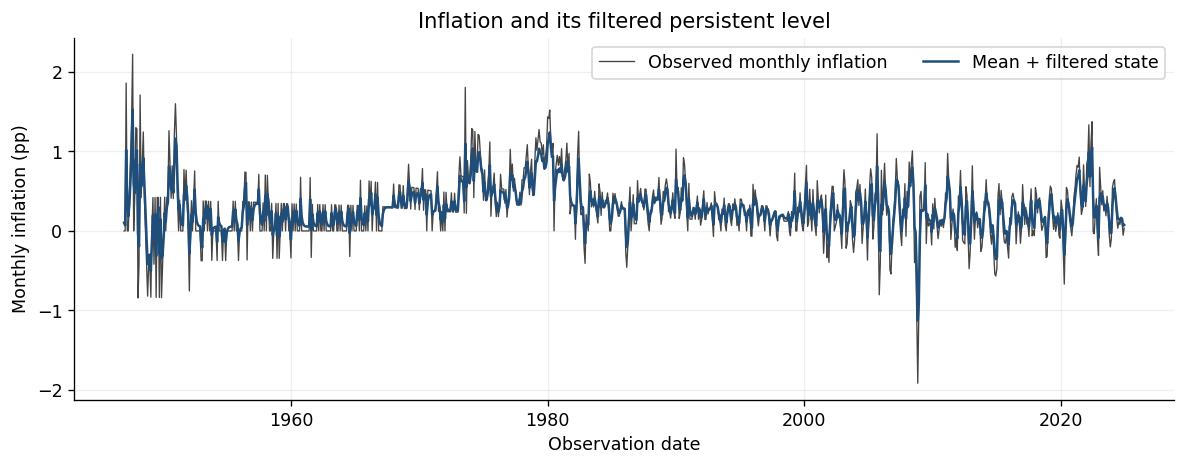

In [17]:
fig_monthly, ax = plt.subplots(figsize=(10,4))
ax.plot(dates, y, color=COLORS['data'], lw=0.8, label='Observed monthly inflation')
ax.plot(dates, monthly_parameters.mu+monthly_states['a_filter'], color=COLORS['monthly'], label='Mean + filtered state')
ax.set_ylabel('Monthly inflation (pp)'); ax.set_xlabel('Observation date')
ax.set_title('Inflation and its filtered persistent level'); ax.legend(ncol=2)
calendar_axis(ax); fig_monthly.tight_layout(); plt.show()

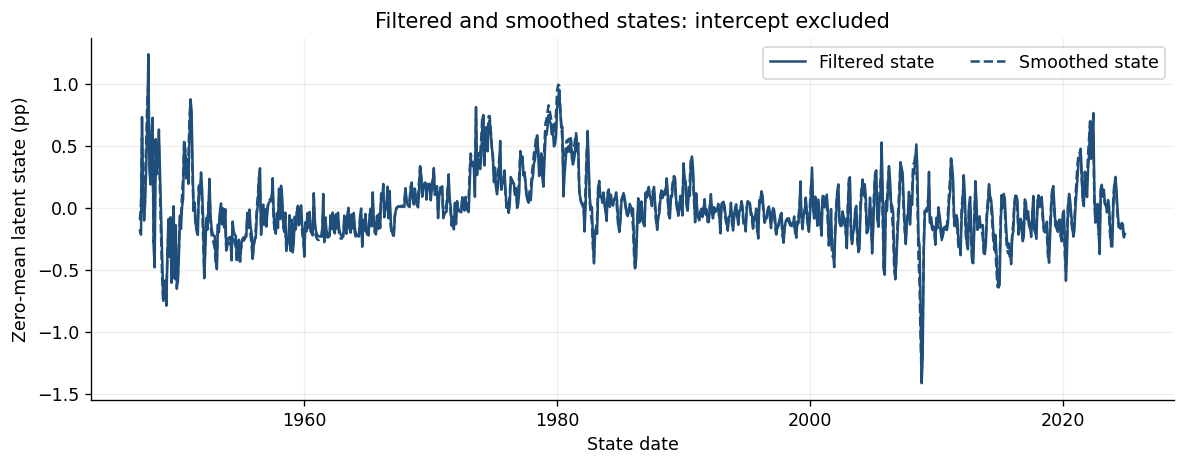

In [18]:
fig_states, ax = plt.subplots(figsize=(10,4))
ax.plot(dates, monthly_states['a_filter'], color=COLORS['monthly'], label='Filtered state')
ax.plot(dates, smoothed_states, color=COLORS['monthly'], ls='--', label='Smoothed state')
ax.set_ylabel('Zero-mean latent state (pp)'); ax.set_xlabel('State date')
ax.set_title('Filtered and smoothed states: intercept excluded'); ax.legend(ncol=2)
calendar_axis(ax); fig_states.tight_layout(); plt.show()

The monthly fit separates transitory observation shocks from a persistent state, but its low phi^12 implies rapid mean reversion over a year. Long historical inflation episodes raise a misspecification concern. Smoothing uses later observations to revise earlier states and reduces conditional uncertainty; that descriptive advantage would leak future information into forecasts. The annual model explores a different observation information set without changing the underlying monthly specification.